# LAB3 - Bayes and k-NN classifiers from scratch

The goal of this notebook is to label every pixel of a satellite image as either **forest** or **urban**, first with a Bayes classifier and then with a k-nearest-neighbours classifier. Both are written with plain NumPy; no machine-learning library is used for fitting or predicting.

The data are three crops of the Sentinel-2 cloudless mosaic (EOX, 2020, true-colour RGB at roughly 10 m per pixel) around Kraków. Ojców National Park provides forest pixels, the centre of Kraków provides urban pixels, and a third crop covering Las Wolski and the western districts of the city, which shares no pixels with the first two, is the image to be classified. The files are in `data/` and can be re-downloaded with `download_data.py`.

The feature used throughout is simply the colour of a pixel, $\mathbf{x} = (R, G, B)$. Each pixel is classified on its own, without looking at its neighbours.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

def load(name):
    return np.asarray(Image.open(f"data/{name}.jpg").convert("RGB")).astype(np.float64)

forest_img = load("forest_train")
urban_img  = load("urban_train")
test_img   = load("test_scene")
print(forest_img.shape, urban_img.shape, test_img.shape)

(608, 641, 3) (498, 572, 3) (774, 1001, 3)


## 1. Bayes classifier

### 1.1 Training pixels

Neither training image is pure. The Ojców crop is mostly farmland, with the forest of the Prądnik valley in the middle, and the Kraków crop contains the Vistula, the Planty ring and several parks. If those pixels were left in, the class models would describe a mixture of land covers instead of one. The training areas are therefore hand-picked rectangles (given as `row0, row1, col0, col1`) that contain only the wanted class: five patches of closed canopy for forest, and the Old Town together with the dense district east of it for urban.

forest training pixels: 43980
urban  training pixels: 34775


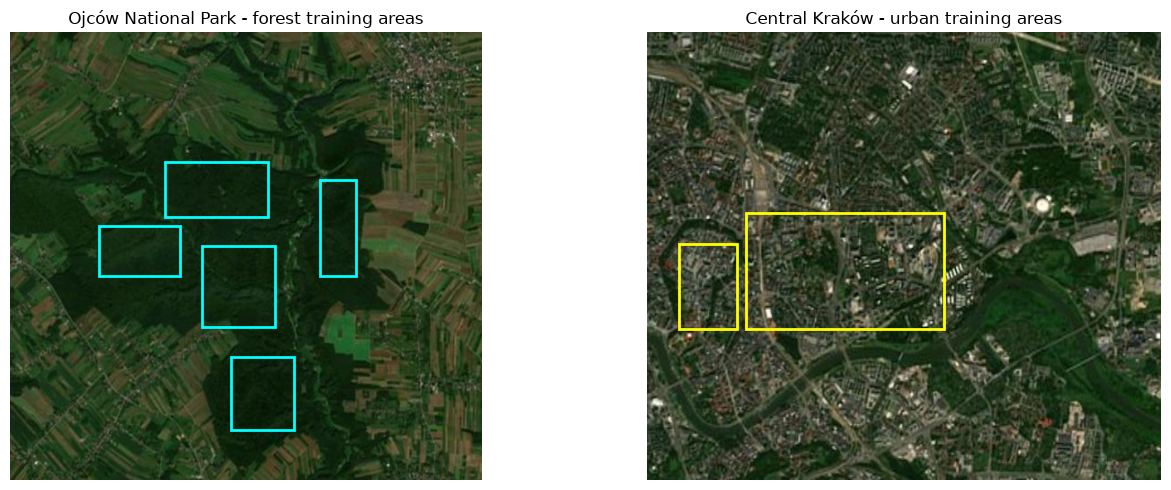

In [2]:
FOREST_BOXES = [(175, 250, 210, 350), (262, 330, 120, 230), (290, 400, 260, 360), (440, 540, 300, 385), (200, 330, 420, 470)]
URBAN_BOXES  = [(235, 330, 35, 100), (200, 330, 110, 330)]

def pixels(img, boxes):
    # stack the pixels of all rectangles into one (N, 3) array
    return np.vstack([img[r0:r1, c0:c1].reshape(-1, 3) for r0, r1, c0, c1 in boxes])

def draw_boxes(ax, boxes, color):
    for r0, r1, c0, c1 in boxes:
        ax.add_patch(Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ec=color, lw=2))

X_forest = pixels(forest_img, FOREST_BOXES)
X_urban  = pixels(urban_img,  URBAN_BOXES)
print("forest training pixels:", len(X_forest))
print("urban  training pixels:", len(X_urban))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(forest_img.astype(np.uint8)); draw_boxes(axes[0], FOREST_BOXES, "cyan")
axes[0].set_title("Ojców National Park - forest training areas")
axes[1].imshow(urban_img.astype(np.uint8)); draw_boxes(axes[1], URBAN_BOXES, "yellow")
axes[1].set_title("Central Kraków - urban training areas")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 1.2 Histograms and a parametric model for the PDFs

A normalised histogram of the training pixels is the estimate of the class-conditional density. The cell below plots it for each colour channel and each class. 

A Gaussian is used as the parametric model, so the only parameters to find are the mean and the std. Their maximum-likelihood estimates are the sample mean and the (biased, divide-by-$N$) sample std:

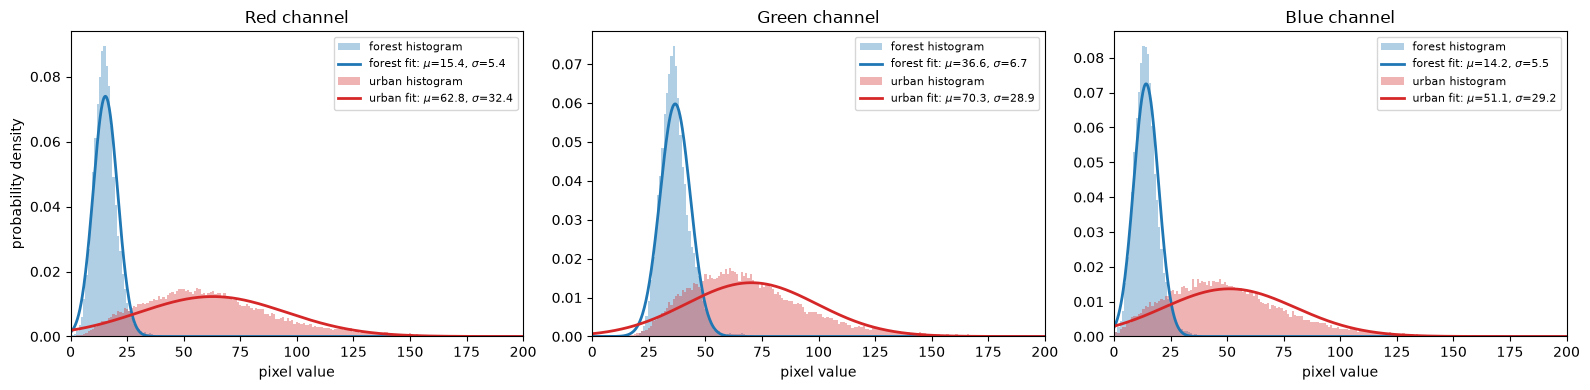

In [3]:
def gauss_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

grid = np.linspace(0, 255, 1000)
bins = np.arange(257) - 0.5
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ch, (ax, name) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    for X, label, col in [(X_forest, "forest", "tab:blue"), (X_urban, "urban", "tab:red")]:
        mu = X[:, ch].sum() / len(X)
        sigma = np.sqrt(((X[:, ch] - mu) ** 2).sum() / len(X))
        ax.hist(X[:, ch], bins=bins, density=True, alpha=0.35, color=col, label=f"{label} histogram")
        ax.plot(grid, gauss_1d(grid, mu, sigma), color=col, lw=2,
                label=rf"{label} fit: $\mu$={mu:.1f}, $\sigma$={sigma:.1f}")
    ax.set_title(f"{name} channel"); ax.set_xlabel("pixel value"); ax.set_xlim(0, 200)
    ax.legend(fontsize=8)
axes[0].set_ylabel("probability density")
plt.tight_layout(); plt.show()

The forest histograms are narrow, so the Gaussian could be a reasonable model, though not the perfect one. The park lies in a deeply cut valley, and sunlit slopes add a tail of brighter pixels, which makes the real peak a little sharper than the fitted curve. Forest is dark and uniform, with a standard deviation of only 5 to 7 grey levels per channel. The urban histograms are much wider and also a little skewed right, because a city is a mix of dark asphalt and shadows from buildings, mid-grey roofs and a long tail of bright concrete and metal. A Gaussian is still good enough here because the two classes differ mainly in how spread out they are, and the Gaussian captures that.

The three channels are not independent. A bright pixel is bright in R, G and B at once, so treating the channels separately would count the same evidence three times. The classifier below therefore uses one multivariate Gaussian per class on the full colour vector, with a mean vector $\mu$ and a covariance matrix $\Sigma$; the parameters are again computed directly from their definitions.

In [4]:
def fit_gaussian(X):
    # maximum-likelihood mean vector and covariance matrix of the rows of X
    mu = X.sum(axis=0) / len(X)
    D = X - mu
    Sigma = D.T @ D / len(X)
    return mu, Sigma

mu_f, Sigma_f = fit_gaussian(X_forest)
mu_u, Sigma_u = fit_gaussian(X_urban)

np.set_printoptions(precision=2, suppress=True)
for name, mu, S in [("forest", mu_f, Sigma_f), ("urban", mu_u, Sigma_u)]:
    std = np.sqrt(np.diag(S))
    print(f"{name}:  mean (R,G,B) = {mu}")
    print(f"covariance =\n{S}")
    print(f"correlation =\n{S / np.outer(std, std)}\n")

forest:  mean (R,G,B) = [15.36 36.62 14.19]
covariance =
[[29.12 33.36 27.29]
 [33.36 44.56 33.15]
 [27.29 33.15 30.27]]
correlation =
[[1.   0.93 0.92]
 [0.93 1.   0.9 ]
 [0.92 0.9  1.  ]]

urban:  mean (R,G,B) = [62.82 70.3  51.05]
covariance =
[[1052.98  914.8   923.33]
 [ 914.8   833.63  831.78]
 [ 923.33  831.78  849.81]]
correlation =
[[1.   0.98 0.98]
 [0.98 1.   0.99]
 [0.98 0.99 1.  ]]



The correlation matrices confirm the point about dependent channels: the correlations between channels are about 0.9 in the forest class and 0.98 in the urban class, which is why the full covariance matrix is kept. The urban variances are also roughly 20 to 35 times larger than the forest ones.

### 1.3 The Bayes test

For every pixel the question is which class is more probable given its colour. Bayes' rule answers it by combining two things: how well the colour fits the class model (the likelihood, read from the fitted Gaussian) and how common the class is expected to be before looking at the pixel (the prior). The pixel is assigned to the class for which the product of the two is larger. This choice gives the lowest possible probability of error, as long as the models describe the data correctly.

In the code the comparison is done on logarithms. Far from the class mean the Gaussian values become so small that the computer would round them to zero, and the logarithm avoids this without changing which class wins. Each class gets a score made of three parts: how far the pixel is from the class mean, measured in units of the class spread (the Mahalanobis distance), a penalty for classes that are spread widely, and the logarithm of the prior. The class with the higher score wins, because forest and urban have very different spreads, the border between them in colour space is curved and not a flat plane.

The number of training pixels per class only reflects how large the rectangles were drawn and says nothing about how much forest the test scene contains, so using counts as priors (settled 0.5) wouldnt be justified.

In [5]:
def discriminant(X, mu, Sigma, prior):
    D = X - mu
    Sigma_inv = np.linalg.inv(Sigma)
    maha = np.einsum("ij,jk,ik->i", D, Sigma_inv, D)      # (x-mu)^T Sigma^-1 (x-mu) for each row
    return -0.5 * maha - 0.5 * np.log(np.linalg.det(Sigma)) + np.log(prior)

def bayes_classify(X, prior_urban=0.5):
    # returns the label (0 = forest, 1 = urban) and the posterior P(urban | x)
    g_f = discriminant(X, mu_f, Sigma_f, 1 - prior_urban)
    g_u = discriminant(X, mu_u, Sigma_u, prior_urban)
    posterior_urban = 1.0 / (1.0 + np.exp(np.clip(g_f - g_u, -700, 700)))
    return (g_u > g_f).astype(int), posterior_urban

H, W, _ = test_img.shape
X_test = test_img.reshape(-1, 3)
labels, post = bayes_classify(X_test)
bayes_map = labels.reshape(H, W)
post_map  = post.reshape(H, W)
print(f"pixels labelled forest: {100 * (bayes_map == 0).mean():.1f} %")
print(f"pixels labelled urban:  {100 * (bayes_map == 1).mean():.1f} %")

pixels labelled forest: 32.7 %
pixels labelled urban:  67.3 %


### 1.4 Result on the new image

Each pixel of the test scene is passed through the test and painted **blue if forest** and **red if urban**. The third panel shows the probability that the pixel is urban according to the classifier, which tells how confident each decision is: dark red and dark blue are confident decisions, pale colours are uncertain ones.

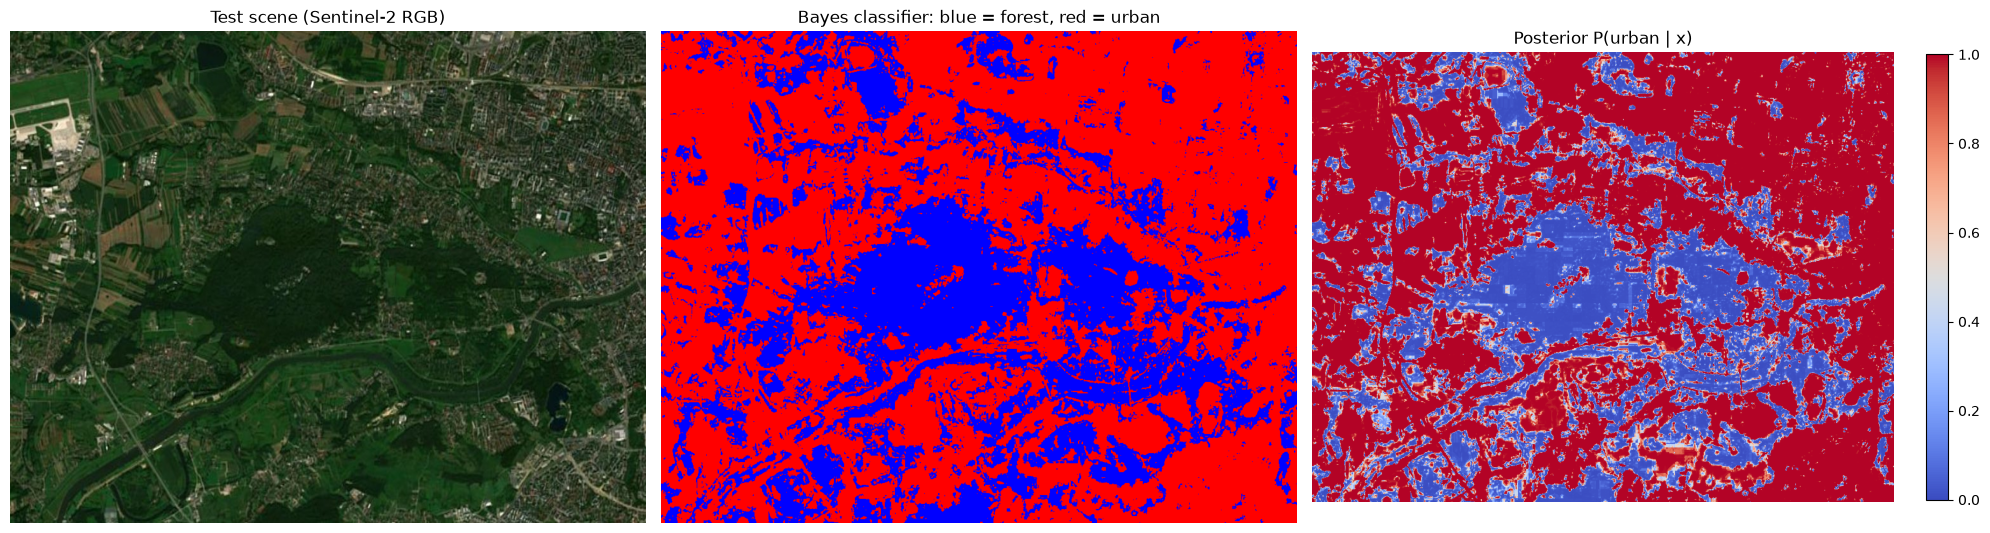

In [6]:
BLUE, RED = np.array([0, 0, 255], np.uint8), np.array([255, 0, 0], np.uint8)

def colorize(label_map):
    return np.where(label_map[..., None] == 1, RED, BLUE)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].imshow(test_img.astype(np.uint8)); axes[0].set_title("Test scene (Sentinel-2 RGB)")
axes[1].imshow(colorize(bayes_map));       axes[1].set_title("Bayes classifier: blue = forest, red = urban")
im = axes[2].imshow(post_map, cmap="coolwarm", vmin=0, vmax=1); axes[2].set_title("Posterior P(urban | x)")
fig.colorbar(im, ax=axes[2], fraction=0.035)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

To measure the quality, four rectangles of the test scene are labelled by hand: two in Las Wolski and the wooded ridge east of it, one in the residential blocks of Krowodrza in the north-east and one in the housing estates in the south-east corner. None of these pixels were used for training. The forest rectangles are smaller (13 400 pixels against 44 200) because the forest itself is small, so result for each class separately says more than the overall accuracy. 

(The same rectangles as here are reused later for k-NN.)

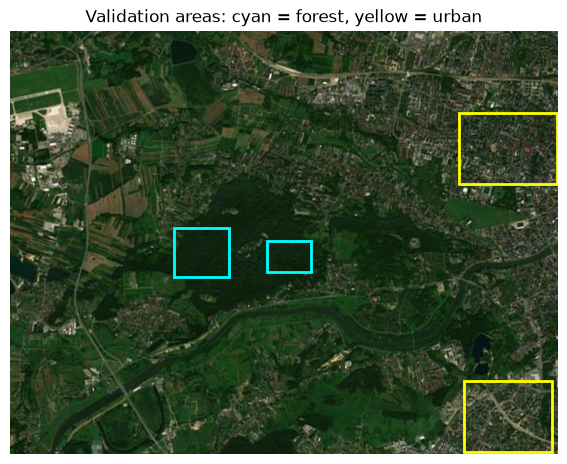

Bayes      accuracy 94.77 % | forest correct 98.13 % | urban correct 93.74 %
confusion matrix (rows: true forest/urban, columns: predicted forest/urban)
 [[13150   250]
 [ 2765 41435]]


In [7]:
VAL_FOREST = [(360, 450, 300, 400), (385, 440, 470, 550)]
VAL_URBAN  = [(150, 280, 820, 1000), (640, 770, 830, 990)]

truth = np.full((H, W), -1)
for r0, r1, c0, c1 in VAL_FOREST: truth[r0:r1, c0:c1] = 0
for r0, r1, c0, c1 in VAL_URBAN:  truth[r0:r1, c0:c1] = 1

def evaluate(label_map, name):
    # confusion matrix and accuracy on the hand-labelled validation pixels
    cm = np.array([[np.sum((truth == t) & (label_map == p)) for p in (0, 1)] for t in (0, 1)])
    recall = cm.diagonal() / cm.sum(axis=1)
    acc = cm.trace() / cm.sum()
    print(f"{name:10s} accuracy {100*acc:.2f} % | forest correct {100*recall[0]:.2f} % | urban correct {100*recall[1]:.2f} %")
    return cm

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.imshow(test_img.astype(np.uint8)); draw_boxes(ax, VAL_FOREST, "cyan"); draw_boxes(ax, VAL_URBAN, "yellow")
ax.set_title("Validation areas: cyan = forest, yellow = urban"); ax.axis("off"); plt.show()

cm_bayes = evaluate(bayes_map, "Bayes")
print("confusion matrix (rows: true forest/urban, columns: predicted forest/urban)\n", cm_bayes)

### 1.5 Discussion

The map picks out the forest well. Las Wolski and the wooded ridge running from it towards the city are solid blue, while the built-up districts in the north-east and south-east, the airport and the main roads are red. On the hand-labelled areas the classifier is right for 94.8 % of the pixels: 98.1 % of the forest pixels and 93.7 % of the urban ones. Most of the urban mistakes are real vegetation inside the city, such as gardens, street trees and shadowed courtyards. At 10 m resolution those pixels really do look like forest, so part of this error comes from labelling a whole rectangle as urban.

The probability map shows that most decisions are made with near-certainty, uncertain pixels appear only along the borders between the classes and along the river. The reason is the forest model is very narrow, so a pixel that is only a little brighter than typical forest dont fits it well so the wide urban model wins by default.

The same behaviour explains the systematic mistakes - the classifier knows only two answers, so every land cover the model has never seen is forced into one of them, and this scene has many. Only 32.7 % of the scene is labelled forest, but the remaining 67.3 % is clearly not only city. Crop fields and mown grass (nearby airport, Błonia) are brighter than forest, do not fit the narrow forest model and come out as urban. Water is split between the two classes: the greenish Vistula goes mostly to forest and the bluish ponds mostly to urban.

The test can only choose well between the classes it was given, so its not a fault of the Bayes test itself. To fix these mistakes we have to add more classes, such as water and farmland, or use a feature that separates them better than colour does. The small square blocks visible in the probability map come from the JPEG compression of the source image, which a pixel-by-pixel classifier simply reproduces.

## 2. k-NN classifier

### 2.1 Method

k-NN does not assume any shape of the class distributions and has no fitting step. The model is simply the set of labelled training pixels. To classify a new pixel, its colour is compared with the colour of every training pixel. The k most similar ones are selected, and the new pixel takes the label that most of them have. Similarity is measured with the ordinary straight-line (Euclidean) distance between colours. This works without any rescaling because the three channels share the same units and range. With two classes an odd k guarantees that the vote never ends in a draw.

The practical weakness of k-NN is its cost -> every pixel to be classified has to be compared with every stored training pixel, test scene has about 775 000 pixels and the training rectangles about 79 000, which would mean tens of billions of comparisons. The training set is a random sample of 2 000 pixels per class, drawn from the same rectangles as before. Taking the same number from each class also keeps the vote fair: with unequal numbers the larger class would win more often only because it has more points everywhere.

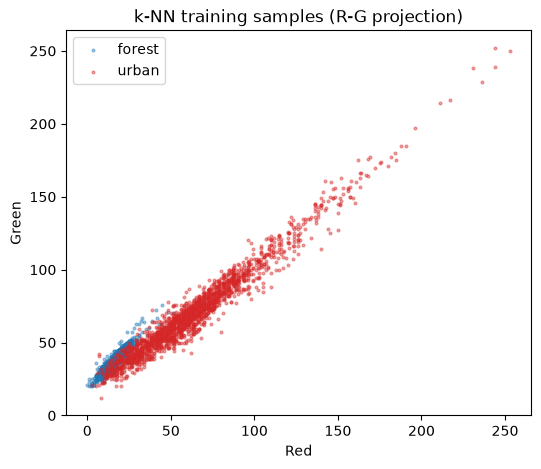

distinct colours: forest 456, urban 1687, present in both classes 60


In [8]:
rng = np.random.default_rng(0)
N_PER_CLASS = 2000

X_train = np.vstack([X_forest[rng.choice(len(X_forest), N_PER_CLASS, replace=False)],
                     X_urban [rng.choice(len(X_urban),  N_PER_CLASS, replace=False)]])
y_train = np.r_[np.zeros(N_PER_CLASS, int), np.ones(N_PER_CLASS, int)]     # 0 = forest, 1 = urban

fig, ax = plt.subplots(figsize=(6, 5))
for c, name, col in [(0, "forest", "tab:blue"), (1, "urban", "tab:red")]:
    ax.scatter(X_train[y_train == c, 0], X_train[y_train == c, 1], s=4, alpha=0.4, color=col, label=name)
ax.set_xlabel("Red"); ax.set_ylabel("Green"); ax.set_title("k-NN training samples (R-G projection)"); ax.legend()
plt.show()

colours_f = set(map(tuple, X_train[y_train == 0].astype(int)))
colours_u = set(map(tuple, X_train[y_train == 1].astype(int)))
print(f"distinct colours: forest {len(colours_f)}, urban {len(colours_u)}, present in both classes {len(colours_f & colours_u)}")

The scatter plot shows what the classifier works with. Forest is a small dense cluster at the dark end, and urban is a long cloud stretched from dark to bright. The two overlap: dark urban pixels (shadows, street trees) have the same colours as forest, and some colours appear in both classes with different labels. This overlap is where the choice of k matters.

The function below computes the distances between a block of pixels and all training samples in one matrix operation, which is much faster than a loop over pixels. It works with squared distances, because taking the square root would not change which samples are closest. The image is processed in blocks of 20 000 pixels so that the table of distances fits in memory. For every pixel the function returns the labels of its five nearest neighbours, ordered from the closest. The expensive search runs only once, and the votes for k = 1, 3 and 5 are all read from the same result.

As limitation: colours are whole numbers from 0 to 255, so several training samples are often at exactly the same distance from a pixel. When these samples compete for the last of the k places, the one that gets it is arbitrary. This affects k = 1 the most, because there a single draw between a forest and an urban sample decides the label.

In [9]:
def nearest_labels(X_query, X_train, y_train, k_max=5, chunk=20000):
    # labels of the k_max nearest training samples of every query row, closest first
    Xt = X_train.astype(np.float32)
    t_sq = (Xt ** 2).sum(axis=1)
    out = np.empty((len(X_query), k_max), dtype=np.int8)
    for s in range(0, len(X_query), chunk):
        q = X_query[s:s + chunk].astype(np.float32)
        d2 = (q ** 2).sum(axis=1)[:, None] + t_sq[None, :] - 2.0 * q @ Xt.T    # squared distances
        idx = np.argpartition(d2, k_max, axis=1)[:, :k_max]                    # k_max smallest, unordered
        order = np.argsort(np.take_along_axis(d2, idx, axis=1), axis=1, kind="stable")
        out[s:s + chunk] = y_train[np.take_along_axis(idx, order, axis=1)]
    return out

def vote(neigh_labels, k):
    # majority vote among the k nearest neighbours (labels are 0/1, so count the ones)
    return (neigh_labels[:, :k].sum(axis=1) > k / 2).astype(int)

t0 = time.time()
neigh = nearest_labels(X_test, X_train, y_train, k_max=5)
print(f"neighbour search for {len(X_test):,} pixels took {time.time() - t0:.1f} s")

knn_maps = {k: vote(neigh, k).reshape(H, W) for k in (1, 3, 5)}

neighbour search for 774,774 pixels took 16.1 s


### 2.2 Results for k = 1, 3 and 5

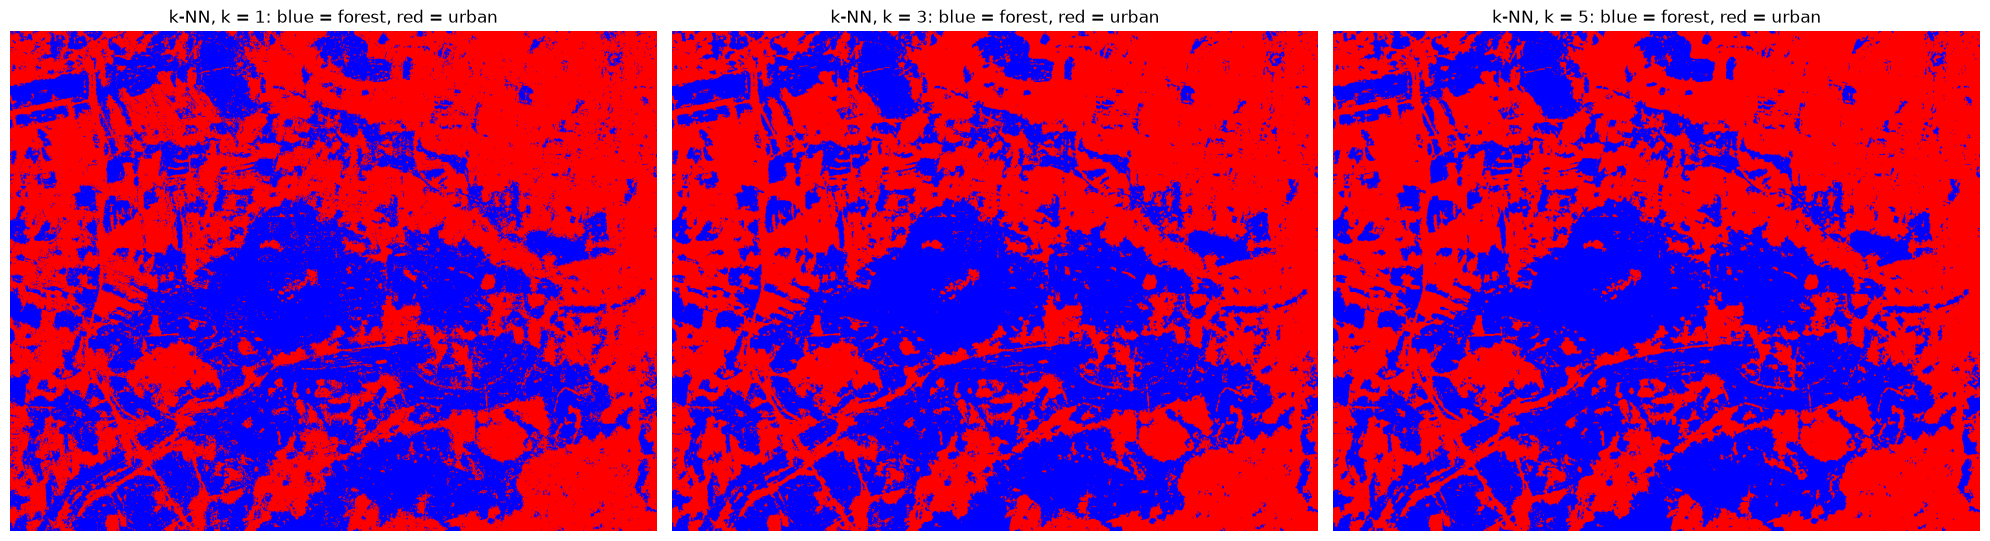

Bayes      accuracy 94.77 % | forest correct 98.13 % | urban correct 93.74 %
k-NN k=1   accuracy 93.82 % | forest correct 96.16 % | urban correct 93.11 %
k-NN k=3   accuracy 94.78 % | forest correct 98.41 % | urban correct 93.68 %
k-NN k=5   accuracy 94.81 % | forest correct 98.57 % | urban correct 93.67 %

Bayes      urban share 67.3 % | isolated pixels  1403 | agreement with Bayes 100.0 %
k-NN k=1   urban share 57.6 % | isolated pixels 11242 | agreement with Bayes 82.3 %
k-NN k=3   urban share 57.8 % | isolated pixels  4645 | agreement with Bayes 84.8 %
k-NN k=5   urban share 58.0 % | isolated pixels  3131 | agreement with Bayes 86.2 %

pixels that change label between k=1 and k=3: 5.68 %
pixels that change label between k=3 and k=5: 3.53 %
pixels that change label between k=1 and k=5: 6.97 %


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (k, m) in zip(axes, knn_maps.items()):
    ax.imshow(colorize(m)); ax.set_title(f"k-NN, k = {k}: blue = forest, red = urban"); ax.axis("off")
plt.tight_layout(); plt.show()

def isolated(label_map):
    # pixels whose label differs from all four direct neighbours ("salt-and-pepper" noise)
    c = label_map[1:-1, 1:-1]
    return int(((c != label_map[:-2, 1:-1]) & (c != label_map[2:, 1:-1]) &
                (c != label_map[1:-1, :-2]) & (c != label_map[1:-1, 2:])).sum())

evaluate(bayes_map, "Bayes")
for k, m in knn_maps.items():
    evaluate(m, f"k-NN k={k}")

print()
for name, m in [("Bayes", bayes_map)] + [(f"k-NN k={k}", m) for k, m in knn_maps.items()]:
    print(f"{name:10s} urban share {100*m.mean():.1f} % | isolated pixels {isolated(m):5d} | agreement with Bayes {100*(m == bayes_map).mean():.1f} %")

print()
for a, b in [(1, 3), (3, 5), (1, 5)]:
    print(f"pixels that change label between k={a} and k={b}: {100*(knn_maps[a] != knn_maps[b]).mean():.2f} %")

The next figure zooms into the northern edge of Las Wolski, where the differences between the settings are easiest to see.

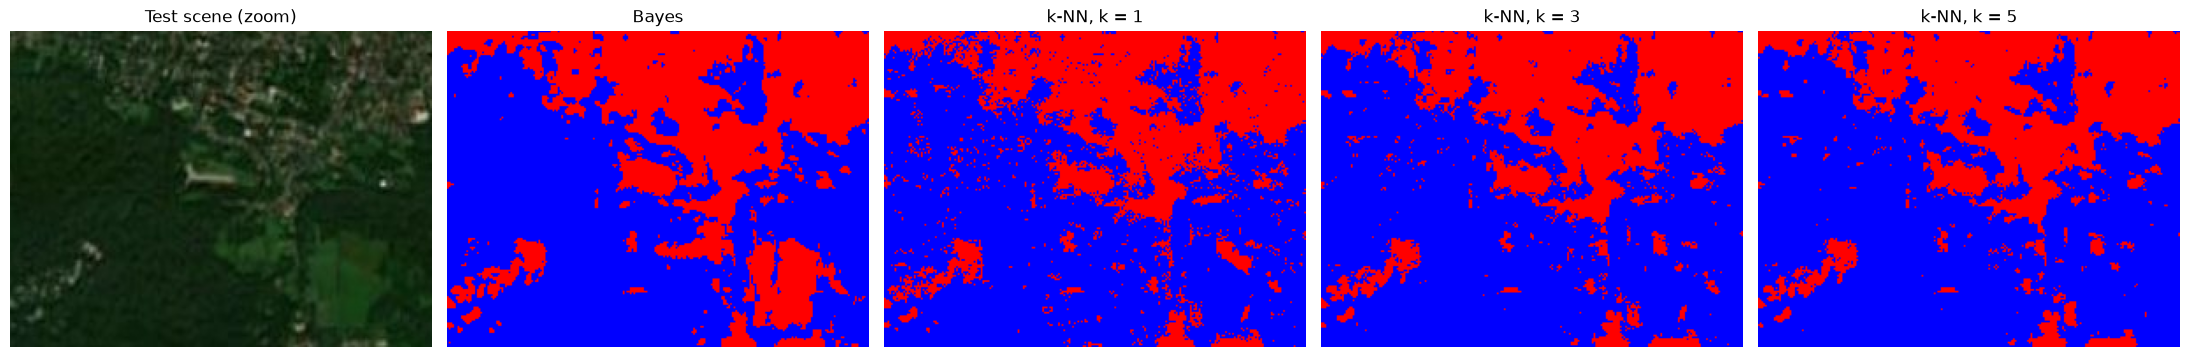

In [11]:
r0, r1, c0, c1 = 250, 430, 420, 660
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].imshow(test_img[r0:r1, c0:c1].astype(np.uint8)); axes[0].set_title("Test scene (zoom)")
axes[1].imshow(colorize(bayes_map[r0:r1, c0:c1]));       axes[1].set_title("Bayes")
for ax, (k, m) in zip(axes[2:], knn_maps.items()):
    ax.imshow(colorize(m[r0:r1, c0:c1])); ax.set_title(f"k-NN, k = {k}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.3 The effect of k

On the hand-labelled areas the accuracy is 93.82% for k = 1, 94.78 % for k = 3 and 94.81% for k = 5, compared with 94.77% for the Bayes classifier. Going from one neighbour to three gains a full percentage point, while going from three to five changes almost nothing. Across the whole image 5.7% of the pixels change label between k = 1 and k = 3, and 3.5% between k = 3 and k = 5. For all other pixels the nearest neighbours belong to one class, so the result is the same whatever k is.

The pixels that do the most changes are the ones whose colour lies in the overlap between the two classes. With k = 1 the label is copied from a single training sample. One unusual sample, for instance a tree pixel inside the urban rectangle, is then enough to mislabel every pixel of a similar colour. In the image this appears as salt-and-pepper noise: 11 242 pixels have a different label than all four of their neighbours, and in the zoomed figure the forest interior is sprinkled with red dots. With more neighbours such unusual samples are outvoted, and the number falls to 4 645 for k = 3 and 3 131 for k = 5. 

**In general, a small k follows the training data very closely and gives a detailed but noisy result, while a larger k gives a smoother and more stable one.**

Forest accuracy rises from 96.2% to 98.4% and then 98.6%. Urban accuracy rises from 93.1% to 93.7% and stays there. Up to k = 5 the smoothing therefore costs nothing that can be measured on this data. The price of a larger k is the loss of fine detail, such as narrow roads in the forest, and it would only become visible for larger values. Most of the benefit comes from the step from 1 to 3. k = 5 is slightly the most accurate and clearly the cleanest, so it is the best choice here.

Compared with Bayes, k-NN with k = 3 or 5 reaches the same accuracy on the hand-labelled areas. The two maps, however, agree on only 82 to 86% of the scene, and k-NN labels much less of it as urban (58 % against 67%). Almost all of the disagreement is in land covers that neither classifier was trained on. Green meadows, the airport grass and the ponds are red in the Bayes map and blue in the k-NN maps. The two methods simply ask different questions. Bayes asks how well a colour fits each class model, and anything brighter than dense forest fits the narrow forest model badly, so the wide urban model takes it. k-NN only asks which training samples are the most similar, and for a medium-green pixel those are the brightest forest samples, because the city sample contains only few strongly green pixels. Brown, bare fields go to urban in both methods. Neither answer is correct, since the true class is missing, and the accuracy figures cannot show this because the hand-labelled rectangles contain only forest and city.

Looking at a cost, the Bayes classifier only stores a mean and a covariance matrix for each class and classifies the whole scene almost instantly. k-NN has to keep the training samples and needed about 16 s even with only 4 000 of them. In return, k-NN does not need any assumption about the shape of the distributions.